# Reviewer 2 geometry survey

## Logical scope

The manuscript tests a universal statement: that a continuous isochrone generated in a steady glacier flow cannot overturn. One admissible, numerically verified counterexample is sufficient to disprove that statement. Repeating the calculation in other geometries addresses a separate scientific question—how selective or transferable the mechanism is—not the logical sufficiency of the counterexample.

Numerical robustness of each counterexample still matters. The positive cases below are checked against mesh spacing, source spacing, trajectory time step, material-map endpoints, energy balance, basal impermeability, trajectory topology, and the prescribed sliding law.

## Common mechanics and diagnostic

Unless stated otherwise, every numerical experiment solves two-dimensional, steady, incompressible, Newtonian full-Stokes flow with

- density $917\,\mathrm{kg\,m^{-3}}$;
- viscosity $2.5\times10^8\,\mathrm{Pa\,yr}$;
- passive basal law $u_t=C\tau_b$ with $C=10^{-5}\,\mathrm{m\,yr^{-1}\,Pa^{-1}}$;
- basal impermeability and a traction-free upper surface;
- surface mass balance diagnosed from the fixed-surface kinematic condition.

Surface particles are labeled by deposition coordinate $x_0$. Their order at common age $\tau$ is

$$J=\left.\frac{\partial x}{\partial x_0}\right|_\tau.$$

$J=0$ is a vertical tangent and $J<0$ is an overturned limb. The value $J=-0.20$ is only a resolved display level, not the physical threshold.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

ellipse = pd.read_csv(ROOT / "data/realistic_geometry_elliptical_family.csv")
ellipse_conv = pd.read_csv(ROOT / "data/realistic_geometry_elliptical_convergence.csv")
ellipse_cuts = pd.read_csv(ROOT / "data/realistic_geometry_elliptical_boundary_sensitivity.csv")
periodic = pd.read_csv(ROOT / "data/realistic_geometry_periodic_screen.csv")
periodic_conv = pd.read_csv(ROOT / "data/realistic_geometry_periodic_convergence.csv")
spike = pd.read_csv(ROOT / "data/finite_spike_survey.csv")
spike_mesh = pd.read_csv(ROOT / "data/finite_spike_mesh_convergence.csv")
spike_dt = pd.read_csv(ROOT / "data/finite_spike_map_convergence.csv")
spike_onset = pd.read_csv(ROOT / "data/finite_spike_accumulation_boundary.csv")
stagnation = pd.read_csv(ROOT / "notebooks/stagnation_flow_results/stagnation_flow_convergence.csv")
wedge = pd.read_csv(ROOT / "notebooks/stagnation_flow_results/stagnation_flow_wedge_convergence.csv")

narrow = ellipse.loc[ellipse.geometry.eq("narrow symmetric trough")].iloc[0]
spike_fine = spike_mesh.loc[spike_mesh.mesh.eq("320 x 48")].iloc[0]
periodic_low = periodic.loc[periodic["minimum J"].idxmin()]
stagnation_fine = stagnation.loc[stagnation.nx.eq(240)].iloc[0]
wedge_fine = wedge[(wedge.branch.eq("shallow/right")) & (wedge.source_count.eq(2401))].iloc[0]

summary = pd.DataFrame([
    {
        "experiment": "narrow finite elliptical trough",
        "scope": "hydrostatic open cuts; finite C",
        "minimum J": narrow["minimum J"],
        "result": "overturns",
    },
    {
        "experiment": "15 periodic finite-thickness beds",
        "scope": "screen through 80 kyr; finite C",
        "minimum J": periodic_low["minimum J"],
        "result": "no overturn found",
    },
    {
        "experiment": "single spike in finite open reach",
        "scope": "complete sampled residence; finite C",
        "minimum J": spike_fine["minimum J"],
        "result": "does not overturn",
    },
    {
        "experiment": "two-sided convergent V basin",
        "scope": "central 5–95% source flux; finite C",
        "minimum J": stagnation_fine["minimum_Jx"],
        "result": "no overturn found",
    },
    {
        "experiment": "JM analytical wedge",
        "scope": "free slip; outside finite-C family",
        "minimum J": wedge_fine["minimum_Jx_to_t_0.6"],
        "result": "overturns",
    },
])
display(summary.style.format({"minimum J": "{:.4f}"}))

,experiment,scope,minimum J,result
0,narrow finite elliptical trough,hydrostatic open cuts; finite C,-0.9597,overturns
1,15 periodic finite-thickness beds,screen through 80 kyr; finite C,0.4297,no overturn found
2,single spike in finite open reach,complete sampled residence; finite C,0.2583,does not overturn
3,two-sided convergent V basin,central 5–95% source flux; finite C,0.9235,no overturn found
4,JM analytical wedge,free slip; outside finite-C family,-1.1312,overturns


## Additional positive geometry: a narrow trough

A finite narrow elliptical trough is the strongest additional counterexample. It has 150 m maximum thickness, 70 m thickness at both open cuts, 250 m vertical radius, and 175 m horizontal radius. The 15, 10, and 7.5 m meshes give $J_{\min}=-0.95951$, $-0.95970$, and $-0.95969$. They first reach $J<-0.20$ at 1582, 1581, and 1581 yr. At that threshold, 383 of 401 sources remain valid across 112.7 m.

Moving both open cuts changes boundary thickness from 91.8 to 41.3 m; all five tested cut locations still overturn. The left and right hydrostatic boundary powers are individually large and nearly balanced, so this is robustness within an open-boundary family, not evidence of boundary-condition independence.

In [2]:
mesh_rows = ellipse_conv[
    (ellipse_conv["check"] == "mesh")
    & (ellipse_conv["geometry"] == "narrow symmetric trough")
][[
    "target spacing (m)", "minimum J", "first resolved age (yr)",
    "first resolved valid source count", "first resolved valid source span (m)",
    "minimum path u (m/yr)", "relative energy residual"
]]
display(mesh_rows.style.format(precision=6))

display(ellipse_cuts[[
    "left boundary thickness (m)", "minimum J", "first resolved age (yr)",
    "minimum path u (m/yr)", "left-boundary power", "right-boundary power"
]].style.format(precision=5))

,target spacing (m),minimum J,first resolved age (yr),first resolved valid source count,first resolved valid source span (m),minimum path u (m/yr),relative energy residual
0,15.000000,-0.959507,1582.000000,383,112.735028,0.009490,0.000126
1,10.000000,-0.959702,1581.000000,383,112.735028,0.009462,0.000026
2,7.500000,-0.959687,1581.000000,383,112.735028,0.009448,0.000007


,left boundary thickness (m),minimum J,first resolved age (yr),minimum path u (m/yr),left-boundary power,right-boundary power
0,91.76809,-0.99144,1317.00000,0.00345,3115560.54930,-3115534.12633
1,81.57299,-0.97887,1435.00000,0.00668,2137636.69836,-2137410.55685
2,70.00000,-0.95970,1581.00000,0.00946,1342642.49576,-1342645.79765
3,56.74422,-0.93161,1756.00000,0.01159,739613.64560,-739814.91567
4,41.33294,-0.82647,1956.00000,0.01290,324596.02359,-324427.49677


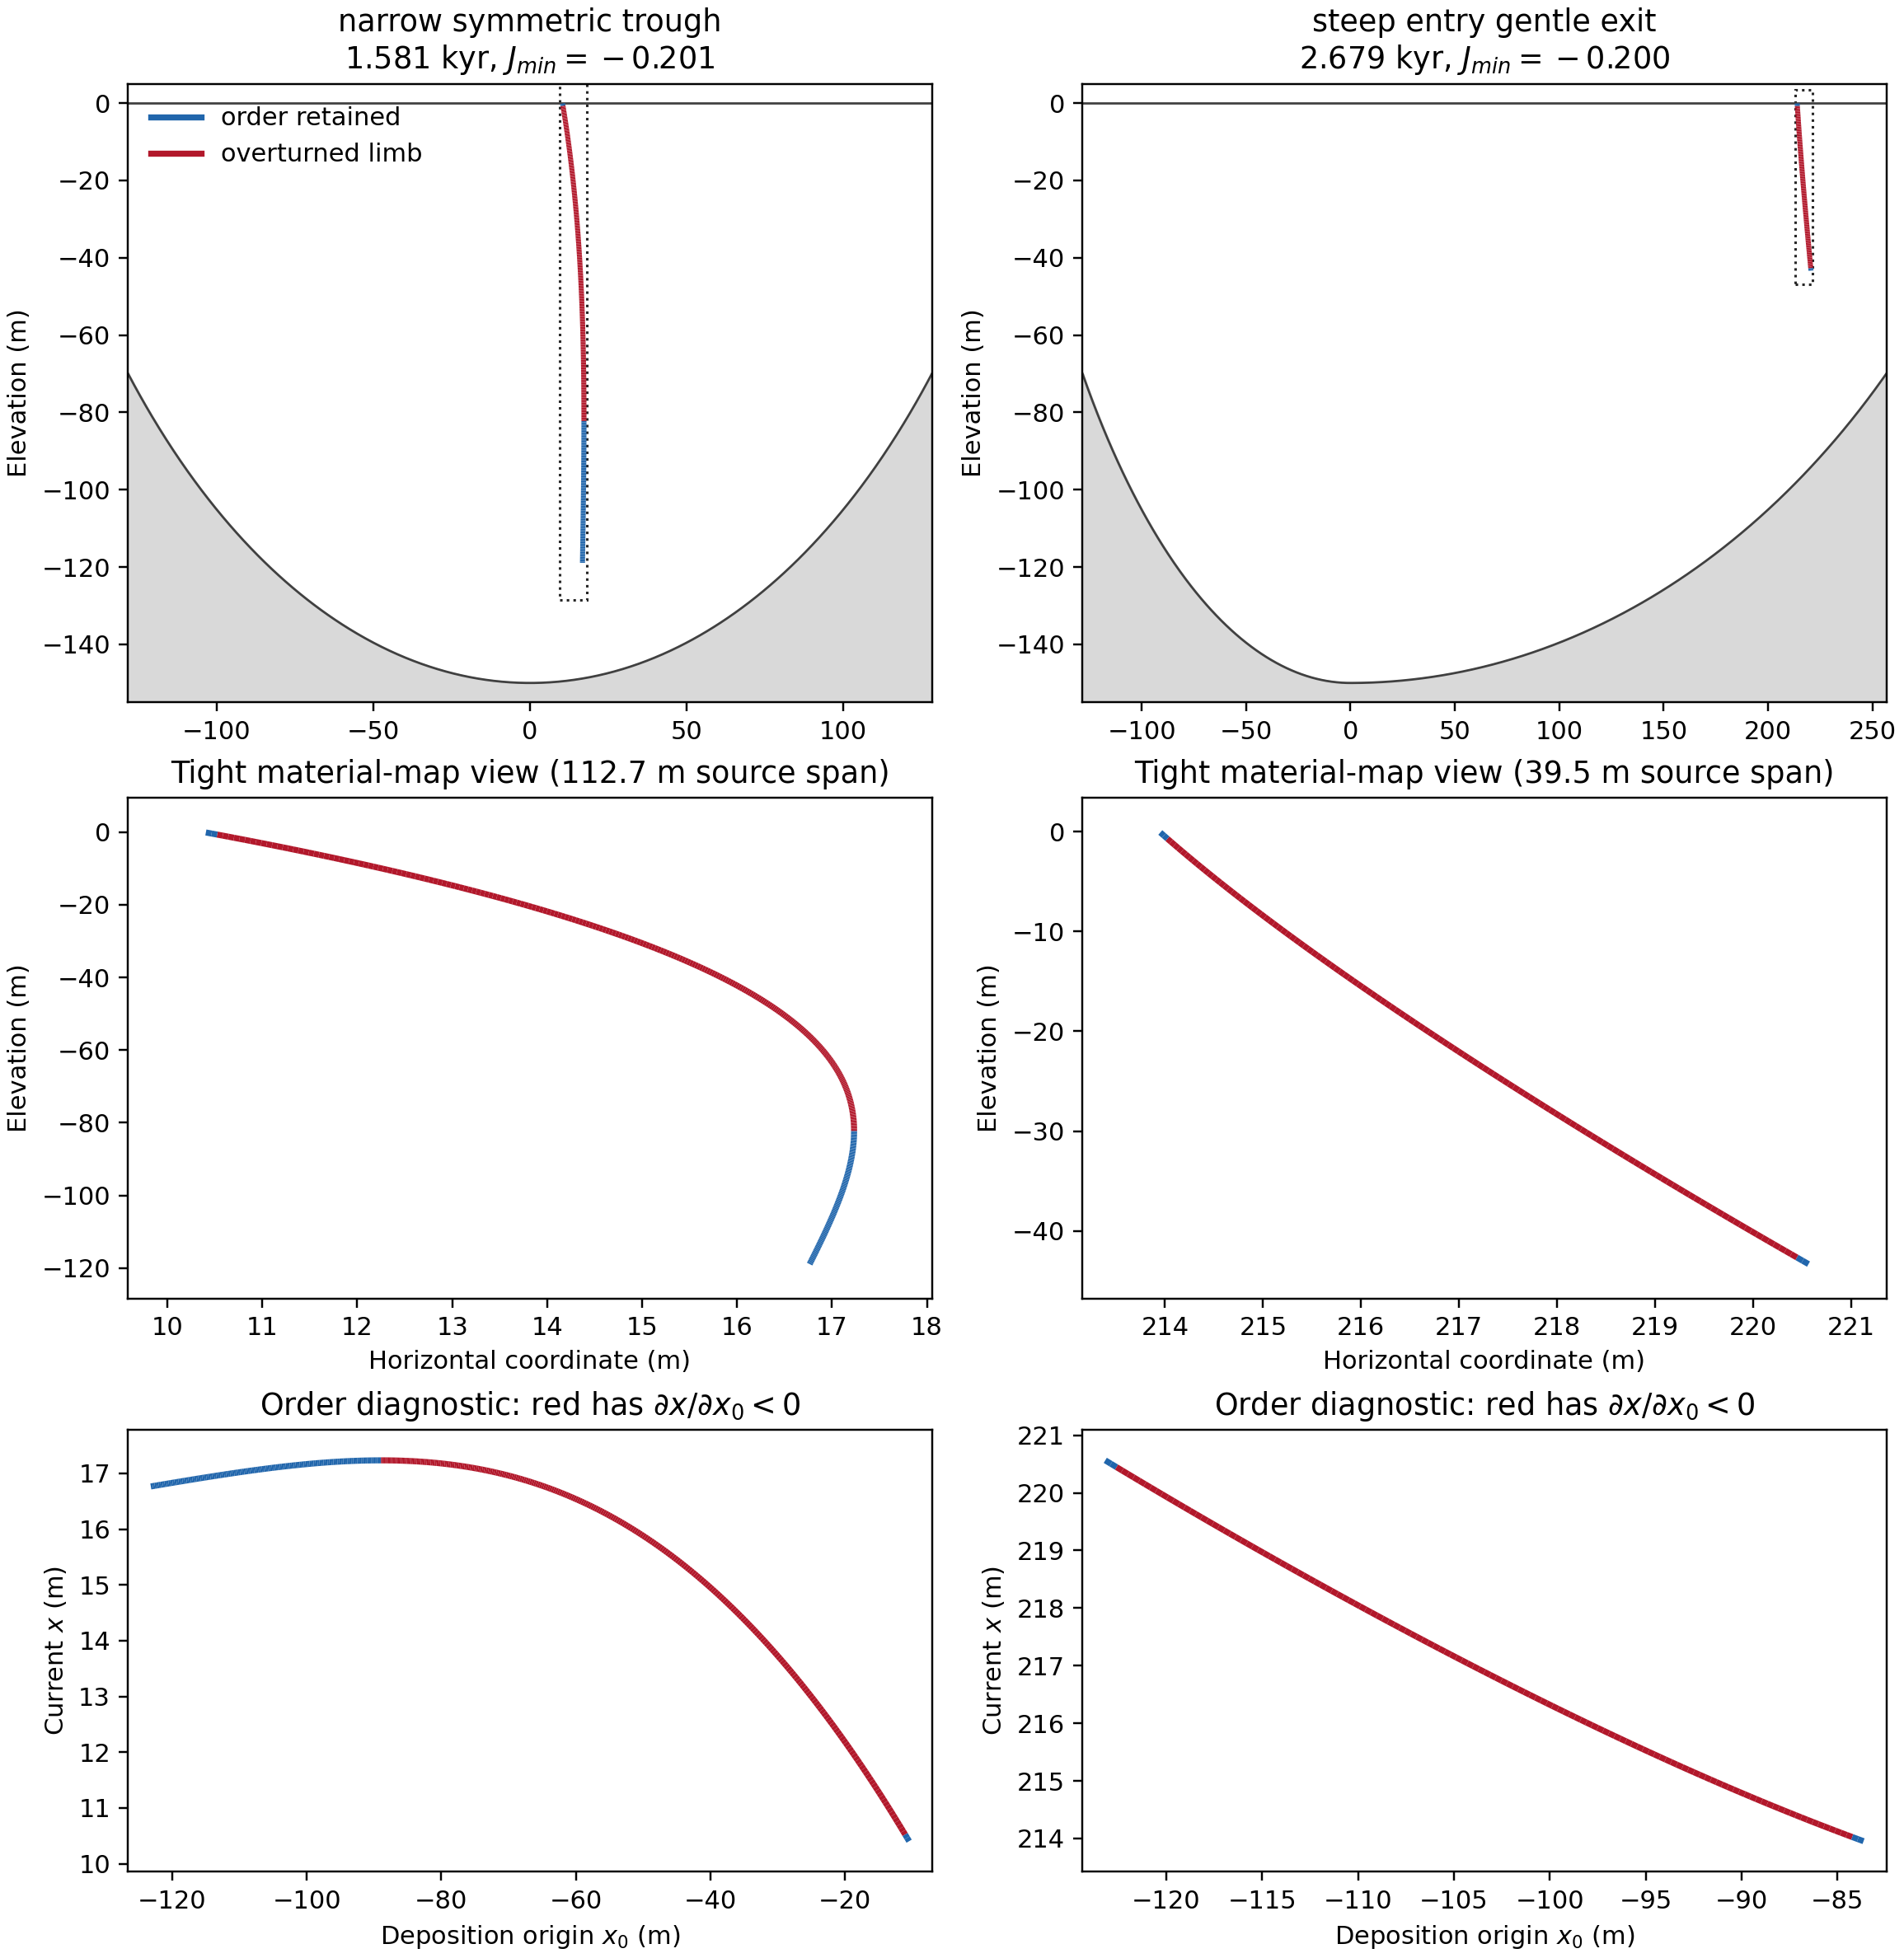

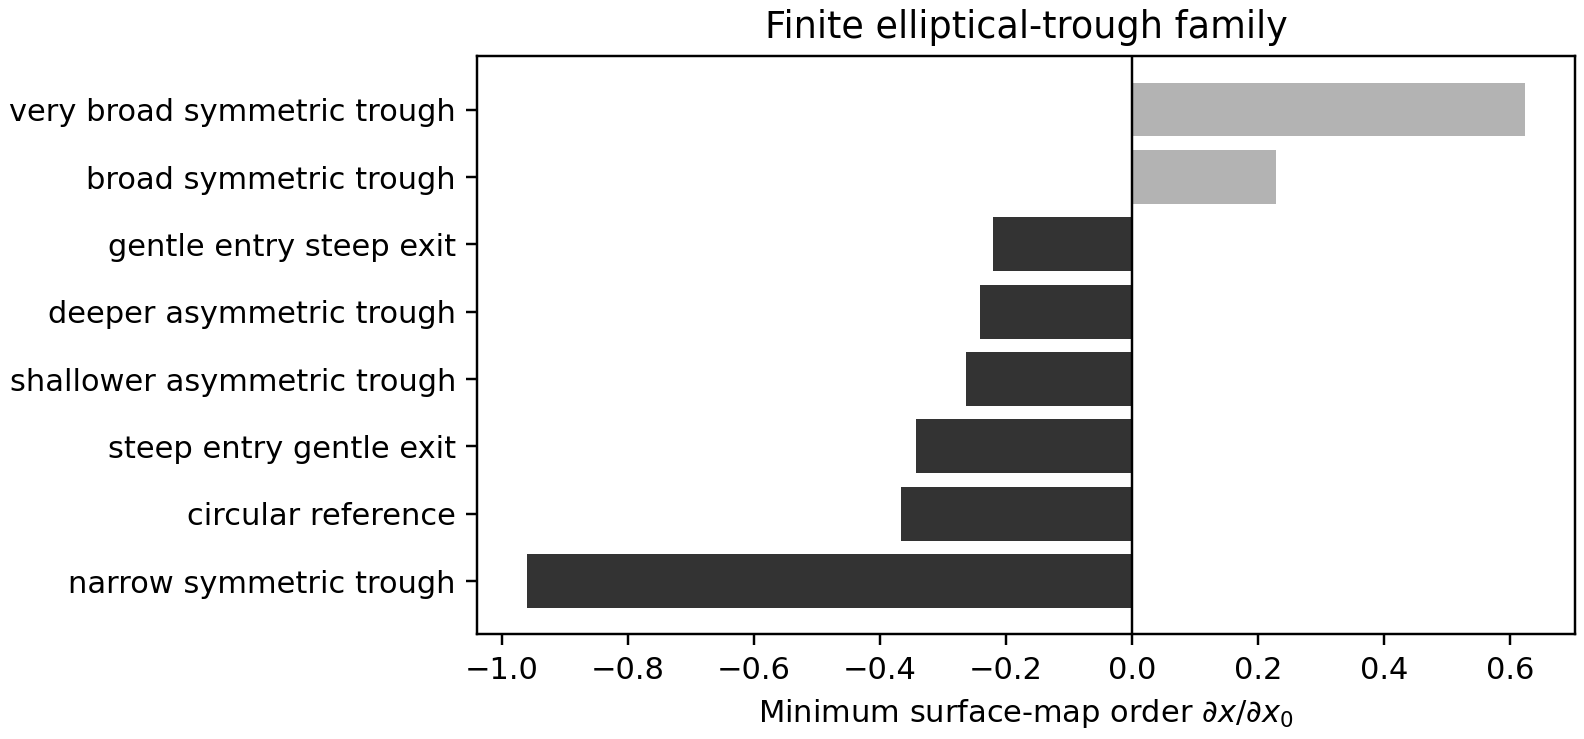

In [3]:
display(Image(filename=str(ROOT / "figures/realistic_geometry_overturned_maps.png"), width=900))
display(Image(filename=str(ROOT / "figures/realistic_geometry_elliptical_family.png"), width=800))

## Finite nonperiodic reach with one steep spike

The spike calculation is a 1.2 km nonperiodic open reach, not a whole divide-to-terminus glacier. Exact flat-slab tractions make the two ends transparent to the reference throughflow. Six isolated raised-cosine spikes range from 80 to 145 m high, reach bed angles of 38–77 degrees, and leave 15–80 m of ice above the crest.

No sampled material map overturns. The closest case is a 145 m spike with 60 m half-width. On 160x24, 240x36, and 320x48 meshes, its minima are 0.2208, 0.2474, and 0.2583. A tangent-deformation equation and neighboring-particle differences agree in sign. All 321 focused sources complete their residence before the 100 kyr ceiling; the finest run's latest exit is 30.53 kyr. Even the source only 0.01 m inside the diagnosed accumulation boundary completes its residence with $J_{\min}=0.2328$.

,mesh,minimum J,minimum neighboring J,age of minimum J (yr),latest last-valid age (yr),active sources at age ceiling
0,160 x 24,0.220816,0.224515,6252.000000,29486.000000,0
1,240 x 36,0.247411,0.250957,6674.000000,30172.000000,0
2,320 x 48,0.258331,0.262361,6894.000000,30528.000000,0


,time step (yr),minimum J,minimum neighboring J,age of minimum J (yr)
0,4.000000,0.258331,0.262368,6892.000000
1,2.000000,0.258331,0.262361,6894.000000
2,1.000000,0.258331,0.262348,6893.000000
3,0.500000,0.258331,0.262353,6893.000000


,source offset from accumulation onset (m),minimum J,age of minimum J (yr),last valid age (yr),completed residence before age ceiling
0,0.010000,0.232813,7038.000000,30546.000000,True
1,0.020000,0.233886,7032.000000,30544.000000,True
2,0.050000,0.237100,7012.000000,30542.000000,True
3,0.100000,0.242439,6982.000000,30540.000000,True
4,0.250000,0.258331,6894.000000,30528.000000,True
5,0.500000,0.284420,6754.000000,30508.000000,True
6,1.000000,0.335236,6504.000000,30458.000000,True
7,2.000000,0.431758,6030.000000,30320.000000,True
8,5.000000,0.677579,4196.000000,29650.000000,True
9,10.000000,0.905680,2076.000000,27918.000000,True


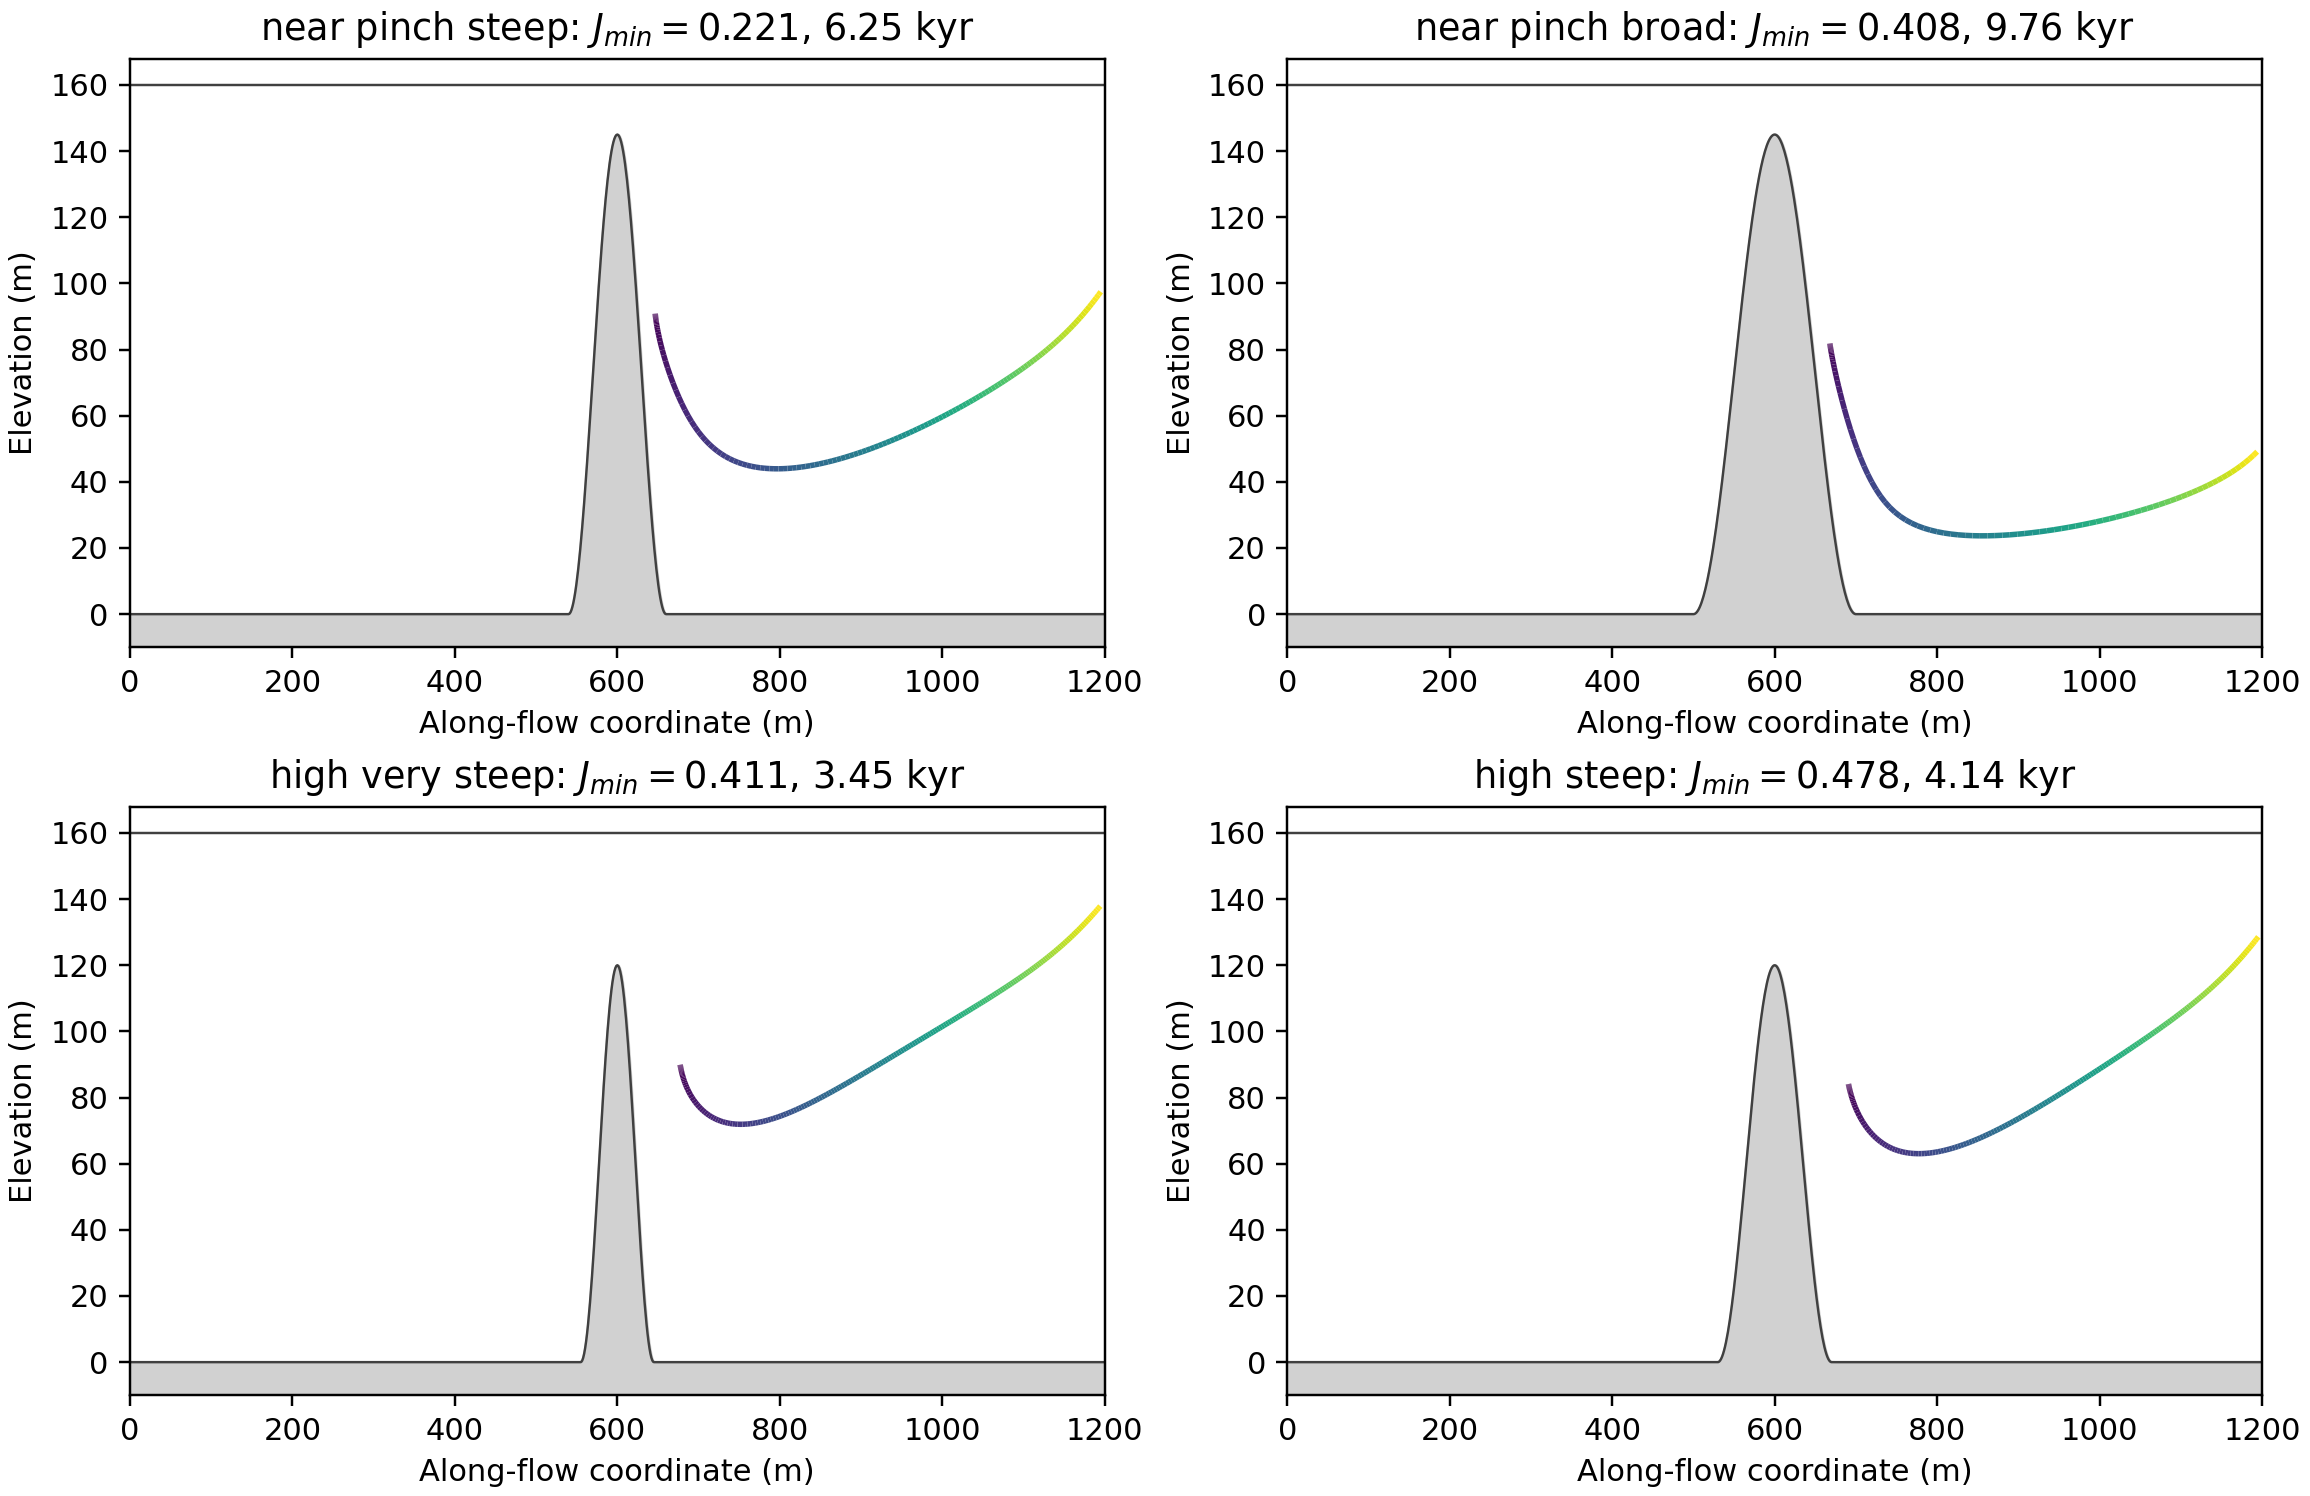

In [4]:
display(spike_mesh[[
    "mesh", "minimum J", "minimum neighboring J", "age of minimum J (yr)",
    "latest last-valid age (yr)", "active sources at age ceiling"
]].style.format(precision=6))

display(spike_dt[[
    "time step (yr)", "minimum J", "minimum neighboring J", "age of minimum J (yr)"
]].style.format(precision=6))

display(spike_onset[[
    "source offset from accumulation onset (m)", "minimum J",
    "age of minimum J (yr)", "last valid age (yr)",
    "completed residence before age ceiling"
]].style.format(precision=6))

display(Image(filename=str(ROOT / "figures/finite_spike_open_boundary.png"), width=850))

## Periodic beds: broad negative screen

Fifteen periodic overdeepening, sill, riegel, and double-obstacle beds remain ordered through 80 kyr. Every case retains some active markers at the cutoff, so these are time-bounded negative results rather than preservation theorems. The three lowest-order cases remain positive on three meshes.

,geometry,minimum J,age of minimum J (yr),valid source count at end
4,steep asymmetric trough 10m,0.42966,24540.00000,52
6,steep reverse trough 25m,0.43174,72350.00000,28
11,basin between narrow riegels,0.45082,19320.00000,33
5,steep asymmetric trough 25m,0.51836,21380.00000,39
13,trough sill doublet,0.56958,18340.00000,49
8,deep valley 25m,0.57790,15290.00000,52
9,overdeepening and exit sill,0.59382,15700.00000,71
0,asymmetric trough 15m 250x75,0.62755,21360.00000,68


,geometry,mesh,minimum J,age of minimum J (yr),valid source count at end
0,steep asymmetric trough 10m,48 x 12,0.39406,25315.00000,79
1,steep asymmetric trough 10m,72 x 18,0.42274,24600.00000,77
2,steep asymmetric trough 10m,96 x 24,0.42417,24790.00000,76
3,steep reverse trough 25m,48 x 12,0.41334,72935.00000,41
4,steep reverse trough 25m,72 x 18,0.46010,73685.00000,44
5,steep reverse trough 25m,96 x 24,0.43029,78850.00000,46
6,basin between narrow riegels,48 x 12,0.42004,19335.00000,51
7,basin between narrow riegels,72 x 18,0.43682,19050.00000,51
8,basin between narrow riegels,96 x 24,0.44150,19095.00000,51


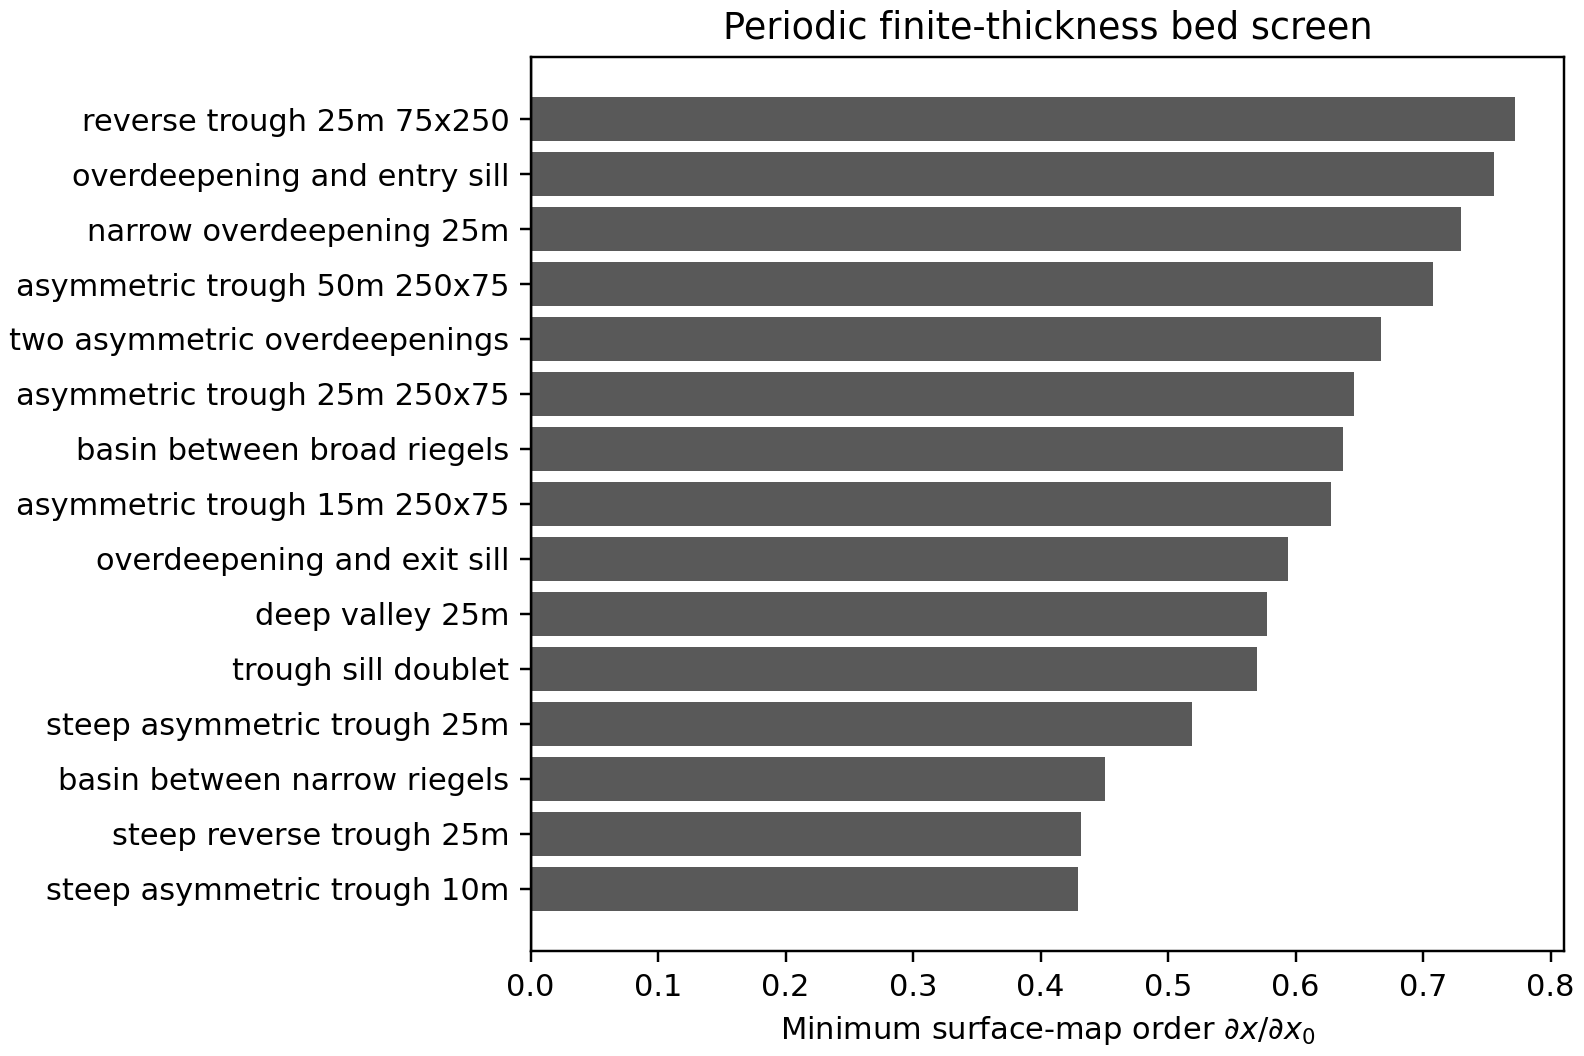

In [5]:
display(periodic.sort_values("minimum J")[[
    "geometry", "minimum J", "age of minimum J (yr)",
    "valid source count at end"
]].head(8).style.format(precision=5))

display(periodic_conv[[
    "geometry", "mesh", "minimum J", "age of minimum J (yr)",
    "valid source count at end"
]].style.format(precision=5))

display(Image(filename=str(ROOT / "figures/realistic_geometry_periodic_screen.png"), width=800))

## Two-sided convergence and the JM stagnation field

The finite-mobility V basin implements the requested steep short left flank, long gentle right flank, two accumulation sources, central convergence/upwelling, and diagnosed central ablation. Endpoint-trimmed maps remain positive: the three-mesh sequence is 0.923588, 0.923549, and 0.923529. Denser source tests remain above 0.887.

The exact analytical JM wedge does overturn its shallow/right source. Its midpoint passes through vertical at dimensionless age $tU_R/R=0.35715$, and sources at least 15 degrees from the basal corner have negative $J$ at the original time $t=0.10$. However, its wedge arms have zero tangential traction and nonzero tangential speed. It is a free-slip benchmark ($C=\infty$), not a member of the requested finite-$C$ family.

,nx,nz,minimum_Jx,minimum_speed,maximum_age_before_exit,overturned_samples,relative_energy_residual
0,120,12,0.9235879,0.0507297,18650.0000000,0,0.0000020
1,180,18,0.9235491,0.0507347,18650.0000000,0,0.0000003
2,240,24,0.9235292,0.0507311,18650.0000000,0,0.0000001


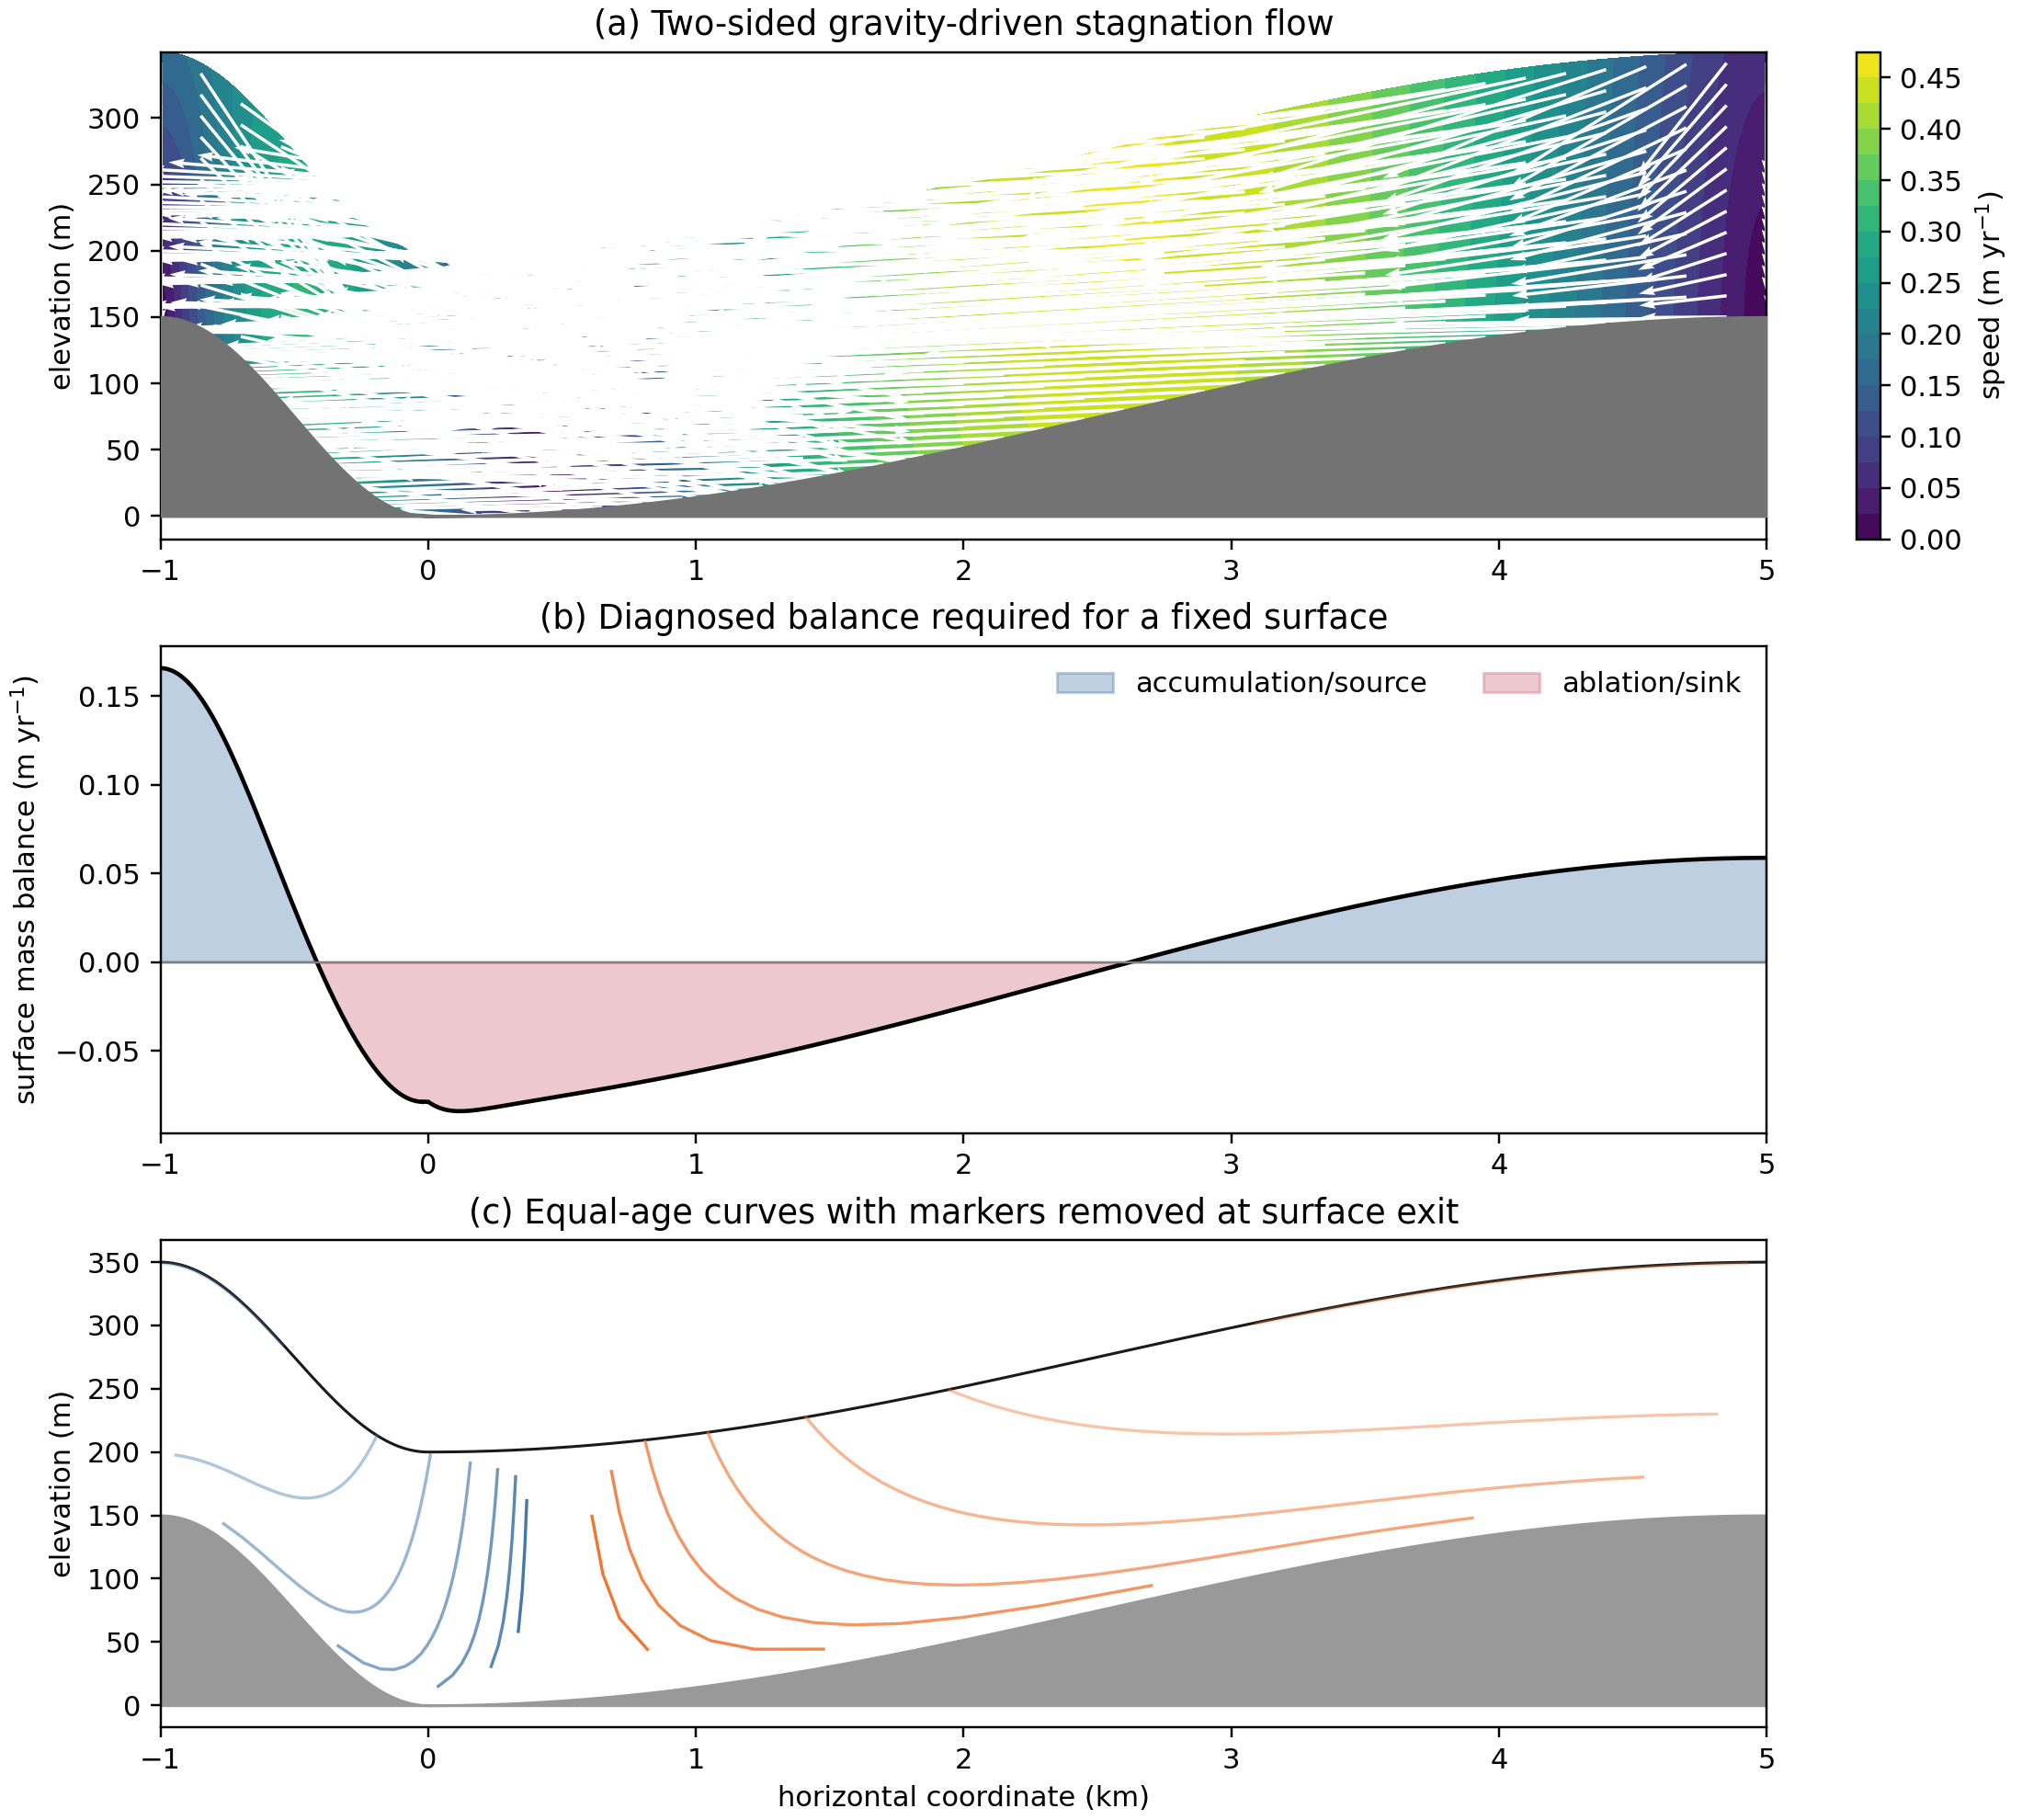

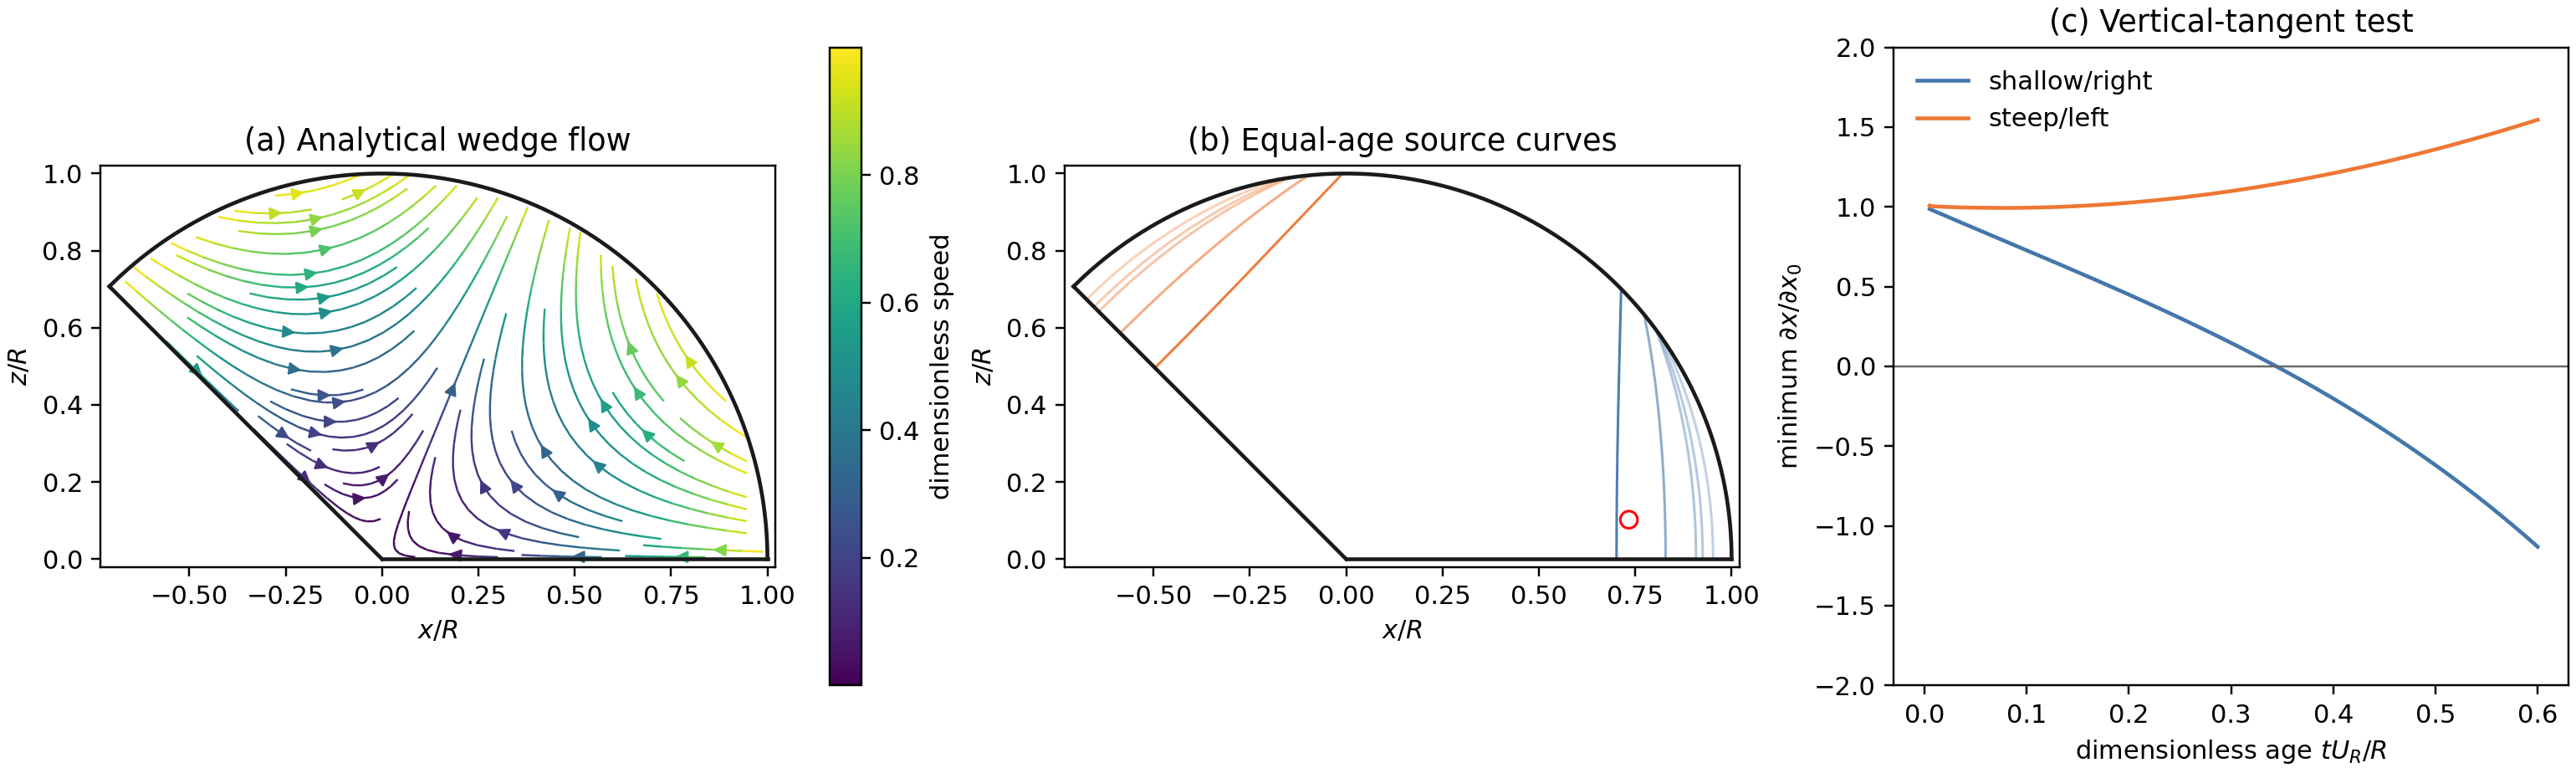

In [6]:
display(stagnation[[
    "nx", "nz", "minimum_Jx", "minimum_speed", "maximum_age_before_exit",
    "overturned_samples", "relative_energy_residual"
]].style.format(precision=7))

display(Image(filename=str(ROOT / "notebooks/stagnation_flow_results/stagnation_flow_summary.png"), width=850))
display(Image(filename=str(ROOT / "notebooks/stagnation_flow_results/stagnation_flow_wedge_benchmark.png"), width=850))

## Interpretation for Reviewer 2

The narrow elliptical trough shows that the original circular arc is not the only steady finite-mobility geometry that overturns. Cut-location, mesh, source-count, and time-step tests support that conclusion. The negative spike, periodic, broad-trough, and convergent-flow results show that the mechanism is selective.

This distinction should be explicit in the response:

1. **Logical sufficiency:** one valid counterexample disproves the universal preservation claim.
2. **Numerical sufficiency:** that example must survive discretization, material-map, energy, boundary-law, and topology checks.
3. **Transferability:** additional geometries test how often the mechanism occurs; they do not change the logic of the counterexample.
4. **Scope:** the new survey establishes a second robust positive family, not prevalence in real glaciers or a reconstruction of Allan Hills.